<center><h1>Simulating the PSS Network</h1></center>
<hr/>

Loads the Antimony model, runs an ODE simulation via
[Tellurium](https://tellurium.readthedocs.io/) / CVODE, and provides
interactive and static trajectory plots plus basic diagnostics.

| Step | Description |
|---|---|
| Load | Read species dict + Antimony model string |
| Simulate | Integrate with CVODE over a defined time horizon |
| Visualise | Interactive (Plotly) and static (Matplotlib) trajectory plots |
| Diagnose | Detect negative concentrations and rank species by max derivative |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import tellurium as te

from typing import Optional

from scripts.utils import (
    ANTIMONY_PATH,
    RED, RESET,
    plt,
)

## Load

In [2]:
antimony = Path("../results/buildAntimony/Antimony.txt").read_text()
# antimony = Path("../data/Antimony_fixed4.txt").read_text()

## Plot Helpers

In [3]:
def sim_to_df(sim) -> pd.DataFrame:
    """Convert a Tellurium simulation array to a tidy DataFrame.

    Args:
        sim: RoadRunner simulation result array.

    Returns:
        Wide DataFrame with a 'time' column and one column per species.
    """
    df          = pd.DataFrame(sim[:, 1:], columns=sim.colnames[1:])
    df['time']  = sim[:, 0]
    return df


def simulate(sim, species_list: Optional[list[str]] = None) -> None:
    """Plot simulation trajectories interactively with Plotly.

    Args:
        sim:          RoadRunner simulation result array.
        species_list: Optional subset of species column names to display.
                      Displays all species when None.
    """
    df = sim_to_df(sim)
    if species_list:
        df = df[['time'] + [s for s in species_list if s in df.columns]]

    fig = px.line(
        df.melt(id_vars='time', var_name='species', value_name='concentration'),
        x='time', y='concentration', color='species',
        title='Simulation Trajectories',
        labels={'time': 'Time', 'concentration': 'Concentration'},
        height=800,
    )
    fig.show()


def simulate_static(sim, species_list: Optional[list[str]] = None) -> None:
    """Plot simulation trajectories as a static Matplotlib figure.

    Args:
        sim:          RoadRunner simulation result array.
        species_list: Optional subset of species column names to display.
                      Displays all species when None.
    """
    df = sim_to_df(sim)
    if species_list:
        df = df[['time'] + [s for s in species_list if s in df.columns]]

    plt.figure(figsize=(12, 6))
    for col in df.columns:
        if col != 'time':
            plt.plot(df['time'], df[col])
    plt.xlabel('Time')
    plt.ylabel('Concentration')
    plt.title('Simulation Trajectories')
    plt.legend().remove()
    plt.tight_layout()
    plt.show()

## Simulate

In [4]:
r = te.loada(antimony)

In [5]:
# r = te.loadAntimonyModel(antimony)
# r.integrator = 'cvode'
# r.integrator.maximum_num_steps = 200000

# checkpoints = [100, 500, 1000, 2000, 5000, 10000]

# for end in checkpoints:
#     try:
#         r.simulate(0, end, points=1000)
#         r.resetToOrigin()
#         print(f"t=0 to {end}: OK")
#     except Exception as e:
#         print(f"t=0 to {end}: FAILED — {e}")
#         break

In [6]:
r.integrator = 'cvode'
# r.integrator.absolute_tolerance = 1e-12 
# r.integrator.relative_tolerance = 1e-6
# r.integrator.maximum_num_steps = 100000
# Turn this OFF if you have fixed your rate laws as described above
# r.integrator.nonnegative = False
# r.integrator.absolute_tolerance = 1e-20
# r.integrator.relative_tolerance = 1e-10
# r.integrator.variable_step_size = True

sim = r.simulate(0, 60_000, points=60_000)

In [7]:
# r = te.loada(antimony)
# print(f"Model loaded — {RED}{len(r.getFloatingSpeciesIds())}{RESET} floating species, "
      # f"{RED}{len(r.getReactionIds())}{RESET} reactions.")

In [8]:
# r.reset()
# r.setIntegrator('cvode')
# r.integrator.relative_tolerance = 1e-8
# r.integrator.absolute_tolerance = 1e-14

# r.setIntegrator('cvode')
# r.integrator.setValue('stiff', True)
# r.integrator.setValue('relative_tolerance', 1e-6)
# r.integrator.setValue('absolute_tolerance', 1e-14)

# r.selections = ['time'] + r.getFloatingSpeciesIds()
# sim = r.simulate(0, 10_000, points = 10_000)

## Visualise

/tmp/ipykernel_1180172/673295212.py:56: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



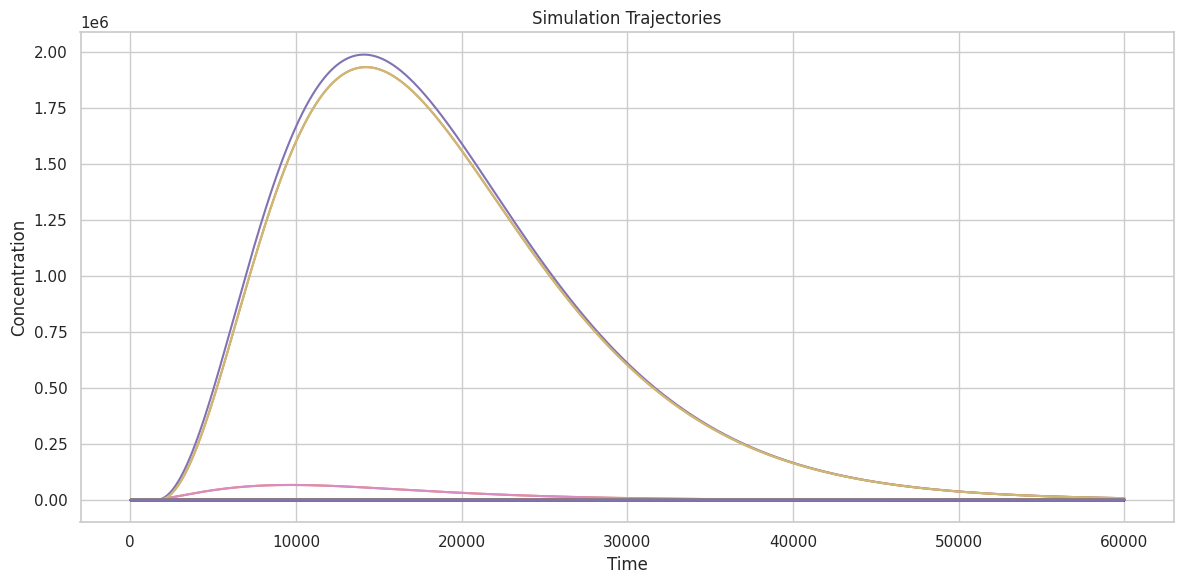

In [9]:
simulate_static(sim)

In [ ]:
df = sim_to_df(sim)
species_cols = [c for c in df.columns if c != 'time']

# Find species still rising at the end of the simulation
still_rising = []
for col in species_cols:
    vals = df[col].values
    # Compare last value to value at t=3000 (roughly)
    idx_3000 = (df['time'] - 3000).abs().idxmin()
    v_3000 = vals[idx_3000]
    v_end = vals[-1]
    if v_end > v_3000 * 1.01 and v_end > 1e-10:
        still_rising.append((col, v_3000, v_end))

still_rising.sort(key=lambda x: x[2], reverse=True)
print(f'Still rising after t=3000: {len(still_rising)}')
for col, v0, v1 in still_rising[:20]:
    print(f'  {col:<50} {v0:.3e} -> {v1:.3e}')

# Plot just the rising ones
simulate(sim, species_list=[col for col, _, _ in still_rising[:20]])

In [ ]:
simulate(sim)

In [ ]:
# simulate(sim, species_list=['[s_OPDA_cyt_m]'])

## Diagnostics

### Negative concentrations

In [ ]:
df = pd.DataFrame(sim, columns=sim.colnames)

# Check only species columns (start with '[')
species_cols = [c for c in df.columns if c.startswith('[')]
neg_mask = df[species_cols] < 0
if neg_mask.any().any():
    first_neg_row = neg_mask.any(axis=1).idxmax()
    print(f"First negative species at row {first_neg_row}")
    print(df[species_cols].iloc[first_neg_row][neg_mask.iloc[first_neg_row]])
else:
    print("No negative species concentrations!")

Root cause: 318 species in your model have consumption reactions but no production reactions. They start at their initial concentration and are purely drained. With a stiff CVODE integrator, adaptive step sizes can cause the integrator to overshoot zero, producing tiny negatives (like -7e-19). These are floating-point artifacts, not real biology.


In [ ]:
df = sim_to_df(sim)

neg_rows = df[(df.drop(columns='time') < 0).any(axis=1)]
if neg_rows.empty:
    print("No negative concentrations detected.")
else:
    first_idx = neg_rows.index[0]
    print(f"First negative value at row {RED}{first_idx}{RESET} "
          f"(time = {df.loc[first_idx, 'time']:.2f})")
    neg_cols = df.loc[first_idx].drop('time')
    print(neg_cols[neg_cols < 0])

### Concentration range

In [ ]:
long_df = df.melt(id_vars='time', var_name='species', value_name='concentration')

print("Minimum:")
print(long_df.loc[long_df['concentration'].idxmin()])
print()
print("Maximum:")
print(long_df.loc[long_df['concentration'].idxmax()])

### Max rate-of-change per species

In [ ]:
time_points  = sim[:, 0]
derivatives  = np.array([r.getRatesOfChange() for _ in time_points])
species_ids  = r.getFloatingSpeciesIds()
max_deriv    = np.max(np.abs(derivatives), axis=0)

ranked = sorted(zip(species_ids, max_deriv), key=lambda x: x[1], reverse=True)

print(f"{'Species':<35}  max |dS/dt|")
print("-" * 55)
for sp, val in ranked:
    print(f"{sp:<35}  {val:.3e}")